In [ ]:
import sympy as sp
sp.init_printing(use_unicode=True)

In [94]:
q = sp.symbols('q')
c = sp.symbols('c')

In [95]:
p4_rec = sp.simplify( (c - (2*q)/(q**2+2)) * (c - (q * (3*q**2 + 4))/(q**2 + 2)) * (c**2 - q*c - 1) - (c - (2*q)/(q**2+2)) * (q**2 + 2) * c - (9*q**4 + 20*q**2 + 12)/((q**2 + 2)**2) * (c**2 - q*c - 1) )

In [96]:
p4_non_rec = sp.simplify( c**4 - 4*q*c**3 + (2*q**2 - 6)*c**2 + 8*q*c + 3 )

In [97]:
p4_rec

In [98]:
p4_non_rec

In [99]:
sp.simplify(p4_rec - p4_non_rec)

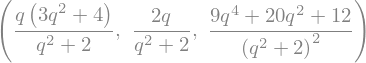

In [100]:
alpha_2_tilde = q * (3*q**2 +4)/(q**2 + 2)
alpha_3_tilde = (2*q)/(q**2 + 2)
beta_3_tilde = (9*q**4 + 20*q**2 + 12)/((q**2 + 2)**2)

alpha_2_tilde, alpha_3_tilde, beta_3_tilde

In [101]:
p_1 = c
p_2 = c**2 - q*c - 1

p_1, p_2

In [102]:
beta_2 = 2 + q**2

beta_2

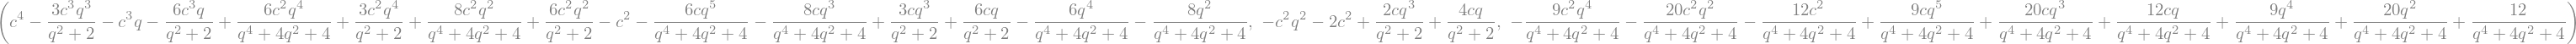

In [103]:
A = (c - alpha_3_tilde) * (c - alpha_2_tilde) * p_2
B = - (c - alpha_3_tilde) * beta_2 * p_1
C = - beta_3_tilde * p_2

P_4 = A + B + C

sp.expand(A), sp.expand(B), sp.expand(C)

In [104]:
P_4_non_rec = c**4 - 4*q*c**3 + (2*q**2 - 6)*c**2 + 8*q*c + 3

P_4_non_rec

In [105]:
sp.simplify(P_4)

In [106]:
sp.simplify(P_4 - P_4_non_rec)

In [107]:
a2,a3,b3 = sp.symbols('a2 a3 b3')

In [108]:
p_2, beta_2, p_1

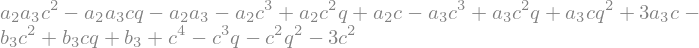

In [109]:
p3_hat = (c - a2) * p_2 - beta_2 * p_1
ansatz = sp.expand((c - a3) * p3_hat - b3 * p_2)
ansatz

{a2: q*(3*q**2 + 4)/(q**2 + 2), a3: 2*q/(q**2 + 2), b3: (9*q**4 + 20*q**2 + 12)/(q**2 + 2)**2}
True


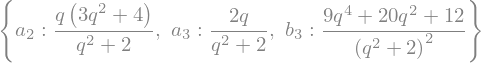

In [110]:
# write ansatz as c^4 + A c^3 + B c^2 + C c + D
A = ansatz.coeff(c, 3)
B = ansatz.coeff(c, 2)
C = ansatz.coeff(c, 1)
D = ansatz.coeff(c, 0)

# target: P4(c;q) = c^4 - 4q c^3 + (2q^2-6) c^2 + 8q c + 3
equations = [sp.Eq(A, -4*q), sp.Eq(B, 2*q**2 - 6), sp.Eq(C, 8*q), sp.Eq(D, 3)]

# 4 equations, 3 unknowns: solve three, check the fourth
sol = sp.solve(equations[:3], [a2, a3, b3], dict=True)[0]
print({k: sp.factor(v) for k, v in sol.items()})
print(sp.simplify(equations[3].lhs.subs(sol) - 3) == 0)
sol